### Лаб 1
#### Предварительная обработка текстовых данных
##### 4 ИВТ_ТИИ Клименко В.А.

In [1]:
import re
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

import spacy
import pymorphy3

from wordcloud import WordCloud

nlp_spacy = spacy.load("ru_core_news_sm")
morph = pymorphy3.MorphAnalyzer()
stop_words = set(stopwords.words('russian'))

DATA_PATH = "lab1_data/raw_texts/"

texts = []
file_names = []

for file_path in sorted(glob.glob(os.path.join(DATA_PATH, "*.txt"))):
    with open(file_path, "r", encoding="utf-8") as f:
        texts.append(f.read())
    file_names.append(os.path.basename(file_path))

print(f"Загружено файлов: {len(texts)}")
print(f"Пример первого файла ({file_names[0]}):\n{texts[0][:200]}")

Загружено файлов: 15
Пример первого файла (news_01_tech.txt):
Компания Apple официально представила новый смартфон iPhone 15 Pro. 
По словам генерального директора Тима Кука, устройство получило титановый корпус 
и улучшенную камеру на 48 мегапикселей. Стоимость


In [2]:
texts_lower = [t.lower() for t in texts]

print("БЫЛО:", texts[0][:80])
print("СТАЛО:", texts_lower[0][:80])

БЫЛО: Компания Apple официально представила новый смартфон iPhone 15 Pro. 
По словам г
СТАЛО: компания apple официально представила новый смартфон iphone 15 pro. 
по словам г


In [3]:
texts_clean = []

for text in texts_lower:
    texts_clean.append(re.sub(r'[^а-яёa-z\s]', '', text))

print("БЫЛО:", texts_lower[0][:80])
print("СТАЛО:", texts_clean[0][:80])

БЫЛО: компания apple официально представила новый смартфон iphone 15 pro. 
по словам г
СТАЛО: компания apple официально представила новый смартфон iphone  pro 
по словам гене


In [5]:
sentences_all = [sent_tokenize(t, language='russian') for t in texts_clean]
tokens_all = []

for sentences in sentences_all:
    tokens = []
    for sentence in sentences:
        tokens.extend(word_tokenize(sentence, language='russian'))
    tokens_all.append(tokens)

print(f"Всего предложений: {sum(len(s) for s in sentences_all)}")
print(f"Всего токенов: {sum(len(t) for t in tokens_all)}")
print(f"Пример токенов первого документа: {tokens_all[0][:15]}")

Всего предложений: 15
Всего токенов: 667
Пример токенов первого документа: ['компания', 'apple', 'официально', 'представила', 'новый', 'смартфон', 'iphone', 'pro', 'по', 'словам', 'генерального', 'директора', 'тима', 'кука', 'устройство']


In [6]:
tokens_no_stop = []

for tokens in tokens_all:
    filtered_tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    tokens_no_stop.append(filtered_tokens)

before = sum(len(t) for t in tokens_all)
after = sum(len(t) for t in tokens_no_stop)

print(f"Токенов до удаления стоп-слов: {before}")
print(f"Токенов после: {after}")
print(f"Удалено: {100 * (before - after) / before:.1f}%")

Токенов до удаления стоп-слов: 667
Токенов после: 499
Удалено: 25.2%


In [7]:
def lemmatize_pymorphy(tokens):
    return [morph.parse(word)[0].normal_form for word in tokens]


stemmer = SnowballStemmer("russian")


def stem_words(tokens):
    return [stemmer.stem(word) for word in tokens]


lemmas_all = [lemmatize_pymorphy(t) for t in tokens_no_stop]
stems_all = [stem_words(t) for t in tokens_no_stop]

comparison = pd.DataFrame({
    'Исходное': tokens_no_stop[0][:10],
    'Лемма': lemmas_all[0][:10],
    'Стем': stems_all[0][:10]
})
print(comparison.to_string(index=False))

    Исходное       Лемма      Стем
    компания    компания    компан
       apple       apple     apple
  официально  официально официальн
 представила представить  представ
       новый       новый       нов
    смартфон    смартфон  смартфон
      iphone      iphone    iphone
         pro         pro       pro
      словам       слово      слов
генерального генеральный генеральн


Топ-20 лемм:
 рубль: 5
 весь: 4
 камера: 3
 первый: 3
 сентябрь: 3
 быть: 3
 сегодня: 3
 день: 3
 писать: 3
 язык: 3
 советовать: 3
 компания: 2
 представить: 2
 новый: 2
 iphone: 2
 директор: 2
 россия: 2
 год: 2
 это: 2
 самый: 2


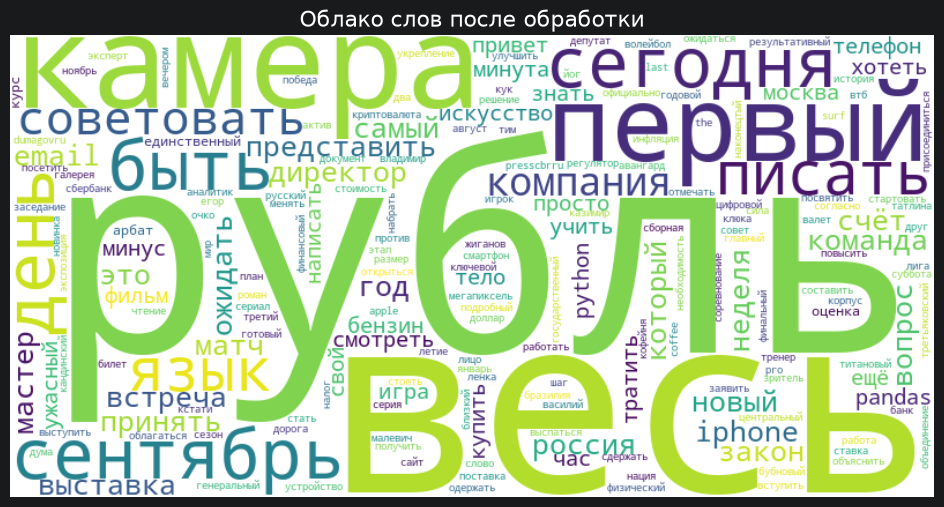

In [9]:
from collections import Counter

all_lemmas = [w for doc in lemmas_all for w in doc]
freq = Counter(all_lemmas)

top20 = freq.most_common(20)
print("Топ-20 лемм:")
for word, count in top20:
    print(f" {word}: {count}")

wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
).generate_from_frequencies(freq)
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Облако слов после обработки', fontsize=16)
plt.savefig('wordcloud_after.png', dpi=150, bbox_inches='tight')
plt.show()

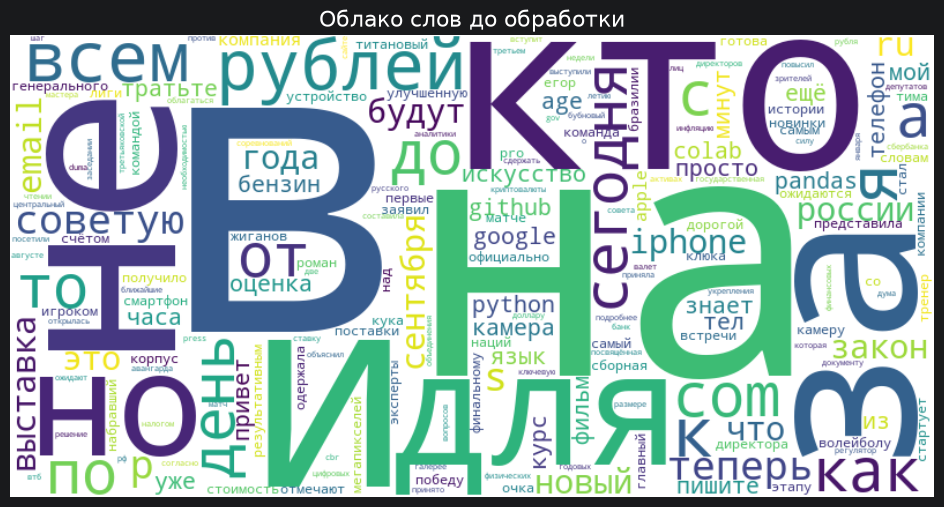

In [11]:
raw_text = ' '.join(texts).lower()

raw_words = re.findall(r'[а-яёa-z]+', raw_text)
raw_freq = Counter(raw_words)

wc_raw = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis'
).generate_from_frequencies(raw_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc_raw, interpolation='bilinear')
plt.axis('off')
plt.title('Облако слов до обработки', fontsize=16)
plt.savefig('wordcloud_before.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
stats = {
    'Метрика': [
        'Всего документов',
        'Слов до обработки (всего)',
        'Уникальных слов до обработки',
        'Слов после обработки (всего)',
        'Уникальных лемм после обработки',
        'Сокращение словаря, %'
    ],
    'Значение': [
        len(texts),
        sum(len(text.split()) for text in texts),
        len(set(word.lower() for text in texts for word in text.split())),
        sum(len(lemmas) for lemmas in lemmas_all),
        len(set(lemma for doc in lemmas_all for lemma in doc)),
        round(
            (1 - len(set(lemma for doc in lemmas_all for lemma in doc)) /
             len(set(word.lower() for text in texts for word in text.split()))) * 100,
            2
        )
    ]
}
print(pd.DataFrame(stats).to_string(index=False))

                        Метрика  Значение
               Всего документов     15.00
      Слов до обработки (всего)    746.00
   Уникальных слов до обработки    589.00
   Слов после обработки (всего)    499.00
Уникальных лемм после обработки    424.00
          Сокращение словаря, %     28.01


### Лаб 1
#### Предварительная обработка текстовых данных
##### 4 ИВТ_ТИИ Клименко В.А.